# `fig-results-overall`: OLS treatment-effect error by dataset, regime, and model

In [1]:
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ASSET_NAME = "fig-results-overall"
ASSET_DIR = Path.cwd()
PAPER_DIR = ASSET_DIR.parent
if not (PAPER_DIR / "microdata_analysis.py").is_file():
    raise FileNotFoundError(f"Open this notebook from manuscript-training-assets/; {PAPER_DIR} has no microdata_analysis.py")
if str(PAPER_DIR) not in sys.path:
    sys.path.insert(0, str(PAPER_DIR))

import microdata_analysis as ma

print(f"Outputs go to {ASSET_DIR / ASSET_NAME}.*")

import matplotlib.ticker
import matplotlib.transforms

Outputs go to /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-overall.*


## Run design

In [2]:
RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
BASE_SLUG = "row1_base_untrained"
TRAINED_SLUGS = ("row2b_wu_ce_oracle", "row3_berke_ce_only", "row5_full_berke_wu_ce_oracle")
VALIDATORS = ("kriner2026", "grummon2025")

ctx = ma.load_microdata_context(
    run_roots=RUN_ROOTS,
    models=MODELS,
    base_slug=BASE_SLUG,
    trained_slugs=TRAINED_SLUGS,
    validators=VALIDATORS,
)
display(ctx.status_grid)

,kev-0.8b,kev-4b,kev-9b
regime,,,
row1_base_untrained,step 0 [test_best ✓],step 0 [test_best ✓],step 0 [test_best ✓]
row2b_wu_ce_oracle,finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best ✓],finished (@928/1395) [test_best ✓]
row3_berke_ce_only,finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best ✓],finished (@256/2730) [test_best ✓]
row5_full_berke_wu_ce_oracle,finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best ✓],finished (@1600/4125) [test_best ✓]


## Labels and formatting (edit wording here)

In [3]:
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}

# Legend order follows this dict.
REGIME_LABELS = {
    BASE_SLUG: "Off-the-shelf",
    "row2b_wu_ce_oracle": "Electricity",
    "row3_berke_ce_only": "Drones",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
REGIME_COLORS = {
    "row2b_wu_ce_oracle": "#2E8B78",
    "row3_berke_ce_only": "#6F5091",
    "row5_full_berke_wu_ce_oracle": "#1B365D",
}
# Vertical nudge of each regime's dots within a dataset row.
REGIME_Y_OFFSETS = {
    BASE_SLUG: 0.0,
    "row2b_wu_ce_oracle": 0.14,
    "row3_berke_ce_only": -0.14,
    "row5_full_berke_wu_ce_oracle": 0.0,
}
# A grey bar joins Off-the-shelf to this regime.
BAR_TO_SLUG = "row5_full_berke_wu_ce_oracle"

DATASET_LABELS = {
    "kriner": "Flights",
    "kantorowicz": "Consumer rights",
    "magistro": "AI & offshoring",
    "grummon": "Food labels",
    "covid": "Vaccines",
}
# Bracketed groups on the left, top to bottom; their datasets must follow DATASET_LABELS order.
ROW_GROUPS = (
    ("Validation", ("kriner",)),
    ("Test\n(price datasets)", ("kantorowicz", "magistro")),
    ("Test\n(non-price datasets)", ("grummon", "covid")),
)

X_LABEL = r"$\mathrm{MSE}_\beta\ (\times 10^3)$"
X_TICKS = (0.5, 1, 2, 5, 10, 20, 50, 100)
MSE_SCALE = 1000.0

TEXT_COLOR = "#2B2B2B"
MUTED_COLOR = "#52514E"
REF_LINE_COLOR = "#6E6A64"
GRID_COLOR = "#D4D2CC"

PANEL_TITLE_SIZE = 11
GROUP_LABEL_SIZE = 8.5
LEGEND_SIZE = 9.0
LEGEND_X = 0.56
DOT_SIZE = 60
GROUP_GAP = 0.45
LEFT_PAD = 2.6

## Draw

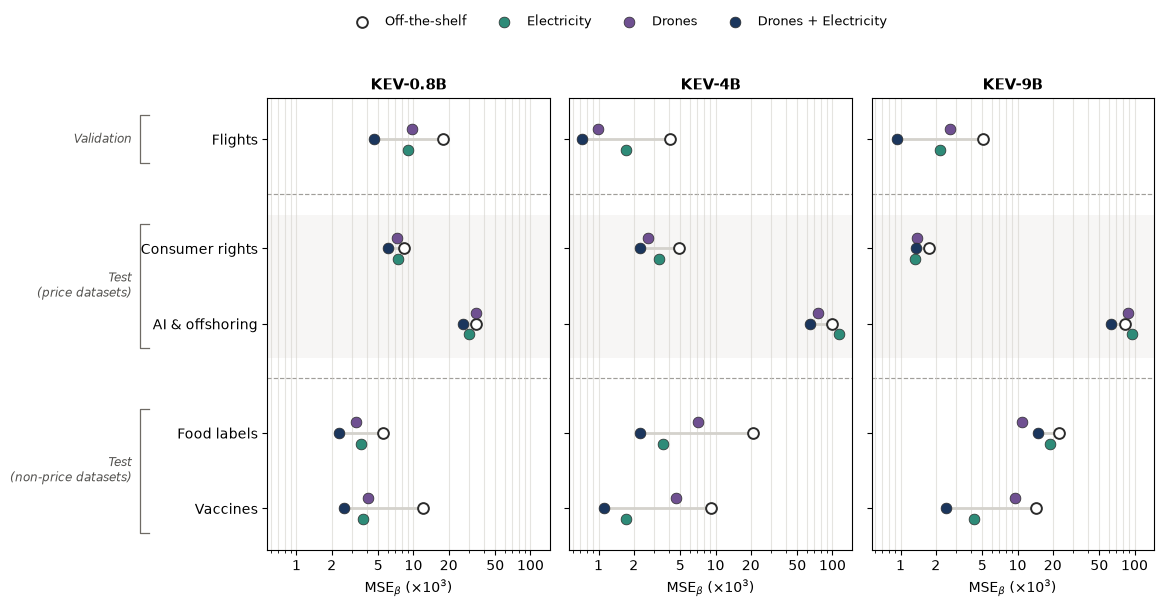

In [4]:
if REGIME_Y_OFFSETS[BAR_TO_SLUG] != REGIME_Y_OFFSETS[BASE_SLUG]:
    raise ValueError("BAR_TO_SLUG must share Off-the-shelf's y offset, or the bar would not meet the dot")
grouped_keys = [key for _, keys in ROW_GROUPS for key in keys]
if grouped_keys != list(DATASET_LABELS):
    raise ValueError(f"ROW_GROUPS datasets {grouped_keys} must match DATASET_LABELS order {list(DATASET_LABELS)}")

# Row positions: one unit per dataset, GROUP_GAP between groups.
y_positions = []
group_spans = []
divider_ys = []
cursor = 0.0
for group_index, (group_label, group_keys) in enumerate(ROW_GROUPS):
    if group_index > 0:
        divider_ys.append(cursor - 0.5 + GROUP_GAP / 2.0)
        cursor += GROUP_GAP
    group_start = cursor
    for _ in group_keys:
        y_positions.append(cursor)
        cursor += 1.0
    group_spans.append((group_label, group_start, cursor - 1.0))
y_positions = np.array(y_positions)
y_min = float(y_positions[0]) - 0.55
y_max = float(y_positions[-1]) + 0.55

fig, axes = plt.subplots(
    1,
    len(MODELS),
    figsize=(3.3 * len(MODELS) + LEFT_PAD, 0.72 * (y_max - y_min) + 1.65),
    sharex=True,
    sharey=True,
    squeeze=False,
)
axes = axes[0]

for ax, model_slug in zip(axes, MODELS):
    regimes_df = ctx.regimes_by_model[model_slug]
    for group_index, (_, group_start, group_end) in enumerate(group_spans):
        if group_index % 2 == 1:
            ax.axhspan(group_start - 0.45, group_end + 0.45, color=GRID_COLOR, alpha=0.18, zorder=0, linewidth=0)
    for divider_y in divider_ys:
        ax.axhline(divider_y, color=REF_LINE_COLOR, linestyle="--", linewidth=0.85, alpha=0.65, zorder=0)

    for y, dataset_key in zip(y_positions, DATASET_LABELS):
        base_value = float(regimes_df.loc[BASE_SLUG, f"{dataset_key}_mse"]) * MSE_SCALE
        end_value = float(regimes_df.loc[BAR_TO_SLUG, f"{dataset_key}_mse"]) * MSE_SCALE
        bar_y = y + REGIME_Y_OFFSETS[BASE_SLUG]
        ax.plot([end_value, base_value], [bar_y, bar_y], color=GRID_COLOR, linewidth=2.0, zorder=1)

    for regime_slug, regime_label in REGIME_LABELS.items():
        values = []
        for dataset_key in DATASET_LABELS:
            value = float(regimes_df.loc[regime_slug, f"{dataset_key}_mse"])
            if np.isnan(value):
                raise ValueError(f"{model_slug}/{regime_slug}: missing {dataset_key}_mse")
            values.append(value * MSE_SCALE)
        dot_ys = y_positions + REGIME_Y_OFFSETS[regime_slug]
        if regime_slug == BASE_SLUG:
            ax.scatter(values, dot_ys, s=DOT_SIZE, facecolors="white", edgecolors=TEXT_COLOR, linewidths=1.4, zorder=3, label=regime_label)
        else:
            ax.scatter(values, dot_ys, s=DOT_SIZE, color=REGIME_COLORS[regime_slug], edgecolors=TEXT_COLOR, linewidths=0.5, zorder=3, label=regime_label)

    ax.set_xscale("log")
    ax.set_xticks(X_TICKS)
    ax.set_xticklabels([f"{tick:g}" for tick in X_TICKS])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_title(MODEL_LABELS[model_slug], fontsize=PANEL_TITLE_SIZE, fontweight="bold")
    ax.set_xlabel(X_LABEL)
    ax.grid(axis="x", color=GRID_COLOR, alpha=0.6, which="both")

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(list(DATASET_LABELS.values()))
axes[0].set_ylim(y_min, y_max)
axes[0].invert_yaxis()

# Group brackets and labels left of the first panel.
bracket_transform = matplotlib.transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
bracket_x = -0.45
bracket_tick = 0.03
for group_label, group_start, group_end in group_spans:
    bracket_top = group_start - 0.32
    bracket_bottom = group_end + 0.32
    axes[0].plot(
        [bracket_x + bracket_tick, bracket_x, bracket_x, bracket_x + bracket_tick],
        [bracket_top, bracket_top, bracket_bottom, bracket_bottom],
        transform=bracket_transform,
        color=REF_LINE_COLOR,
        linewidth=0.9,
        clip_on=False,
    )
    axes[0].text(
        bracket_x - 0.03,
        0.5 * (group_start + group_end),
        group_label,
        transform=bracket_transform,
        fontsize=GROUP_LABEL_SIZE,
        fontstyle="italic",
        color=MUTED_COLOR,
        ha="right",
        va="center",
        clip_on=False,
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(LEGEND_X, 1.02), ncol=len(REGIME_LABELS), fontsize=LEGEND_SIZE, frameon=False)
fig.tight_layout(rect=(0.06, 0.0, 1.0, 0.92))

## Save `fig-results-overall.png` and `.pdf` (the manuscript points here)

In [5]:
for extension in ("png", "pdf"):
    figure_path = ASSET_DIR / f"{ASSET_NAME}.{extension}"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    print(f"Saved {figure_path}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-overall.png
Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-overall.pdf
